In [24]:
import torch
import copy
import torch.nn

import matplotlib.pyplot as plt
from transformers import AutoTokenizer
import random

from laya.scoring import log_score
from laya.multi_objective_reward import multi_obj_reward
from laya.grpo import generate_rollout, grpo_step
from laya.pretrained import PretrainedDecisionModel

from laya.dataset import (
    raw_examples,
    LABELS,
    build_decision_examples,
    move_batch_to_device,
    encode_decision_batch,
)

device = "cpu"

cost matrix for labels


In [25]:
n_labels = len(LABELS)

cost_matrix = torch.ones(n_labels, n_labels, device=device)
cost_matrix.fill_diagonal_(0)

fraud_idx = LABELS.index("Fraud review")
cost_matrix[fraud_idx, :] = 10
cost_matrix[fraud_idx, fraud_idx] = 0

refund_idx = LABELS.index("Refunds")
billing_idx = LABELS.index("Billing")
cost_matrix[refund_idx, billing_idx] = 2
cost_matrix[billing_idx, refund_idx] = 2

In [26]:
# test sample
probabilities = torch.tensor(
    [
        [0.90, 0.05, 0.05, 0.00, 0.00, 0.00],
        [0.80, 0.10, 0.05, 0.05, 0.00, 0.00],
        [0.40, 0.20, 0.10, 0.20, 0.05, 0.05],
    ],
    device=device,
)

outcomes = torch.tensor(
    [0, 3, 3],
    device=device,
)

multi_obj_reward(probabilities, outcomes, cost_matrix)

{'total': tensor([  0.9473, -11.4979,  -1.1047]),
 'scoring': tensor([-0.1054, -2.9957, -1.6094]),
 'correctness': tensor([ True, False, False]),
 'risk': tensor([ 0., 10.,  0.]),
 'operation': tensor([0.0000, 0.0000, 0.3000])}

In [27]:
def reward_fn(probabilities, outcomes):
    result = multi_obj_reward(
        probabilities,
        outcomes,
        cost_matrix,
        confidence_threshold=0.75,
        scoring_weight=0.5,
        utility_weight=1.0,
        risk_weight=1.0,
        review_weight=1.0,
        review_cost=0.3,
    )

    return result["total"]

In [28]:
def reward_a(probabilities, outcomes):
    return log_score(
        probabilities,
        outcomes,
    )


def reward_b(probabilities, outcomes):
    result = multi_obj_reward(
        probabilities,
        outcomes,
        cost_matrix,
        scoring_weight=0.0,
    )
    return result["total"]


def reward_c(probabilities, outcomes):
    result = multi_obj_reward(
        probabilities,
        outcomes,
        cost_matrix,
        scoring_weight=0.5,
    )
    return result["total"]


reward_fn_l = [reward_a, reward_b, reward_c]

In [29]:
model_name = "bert-base-uncased"

In [30]:
# train data
tokenizer = AutoTokenizer.from_pretrained(model_name)

examples = build_decision_examples(raw_examples, LABELS, seed=42)

# train valid split
rng = random.Random(123)

indices = list(range(len(examples)))
rng.shuffle(indices)

cut = 48
train_indices = indices[:cut]
validate_indices = indices[cut:]

train_examples = [examples[e] for e in train_indices]
validate_examples = [examples[e] for e in validate_indices]

train_batch = encode_decision_batch(train_examples, tokenizer)
validate_batch = encode_decision_batch(validate_examples, tokenizer)

train_targets = torch.tensor(
    [e["target"] for e in train_examples], dtype=torch.long
).to(device)
validate_targets = torch.tensor(
    [e["target"] for e in validate_examples], dtype=torch.long
).to(device)

train_batch = move_batch_to_device(train_batch, device)
validate_batch = move_batch_to_device(validate_batch, device)

In [31]:
sft_model = PretrainedDecisionModel(model_name, decision_hidden_dim=128)
sft_model.load_state_dict(
    torch.load("../model/sft_model.pt", map_location="cpu", weights_only=True)
)
sft_model = sft_model.to(device)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20076.65it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [32]:
reference_model = copy.deepcopy(sft_model)

reference_model.eval()  # no train
for para in reference_model.parameters():
    para.requires_grad = False

train


In [33]:
def run_train(reward_fn):
    grpo_model = copy.deepcopy(sft_model)

    for para in grpo_model.backbone.parameters():
        para.requireds_grad = False

    optimizer = torch.optim.AdamW(grpo_model.decision_head.parameters(), lr=1e-5)

    loss_history = []
    policy_loss_history = []
    kl_history = []
    reward_history = []

    n_rollouts = 100
    updates_per_rollout = 3

    for step in range(n_rollouts):
        rollout = generate_rollout(
            model=grpo_model,
            input_ids=train_batch["input_ids"],
            attention_mask=train_batch["attention_mask"],
            option_marker_mask=train_batch["option_marker_mask"],
            outcomes=train_targets,
            reward_fn=reward_fn,
            n_candidates=32,
            exploration_std=0.2,
        )

        reward_history.append(rollout["rewards"].mean().item())

        for update in range(updates_per_rollout):
            loss, policy, kl = grpo_step(
                grpo_model,
                reference_model,
                optimizer,
                train_batch["input_ids"],
                train_batch["attention_mask"],
                train_batch["option_marker_mask"],
                rollout,
                exploration_std=0.2,
                clip_epsilon=0.2,
                kl_beta=0.01,
            )

            loss_history.append(loss)
            policy_loss_history.append(policy)
            kl_history.append(kl)

    return {
        "func": reward_fn.__name__,
        "loss_history": loss_history,
        "policy_loss_history": policy_loss_history,
        "kl_history": kl_history,
        "reward_history": reward_history,
    }

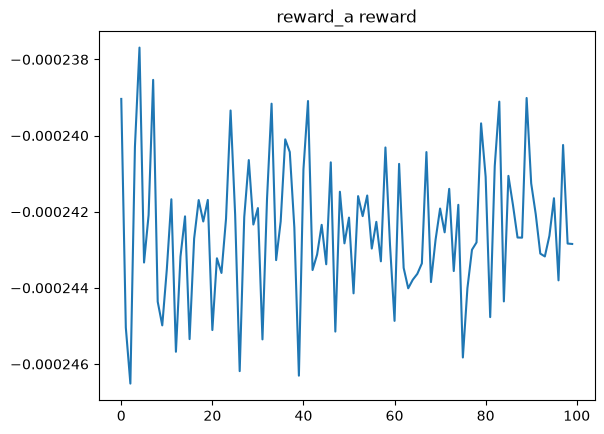

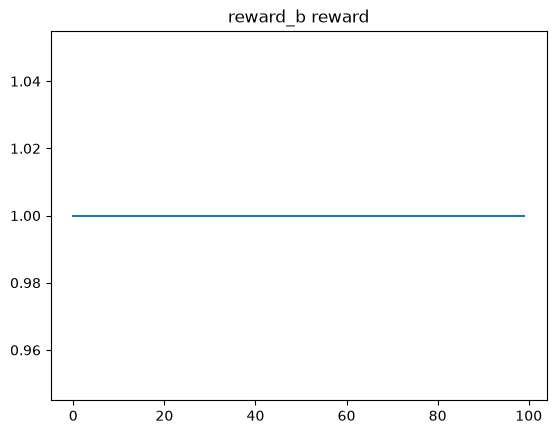

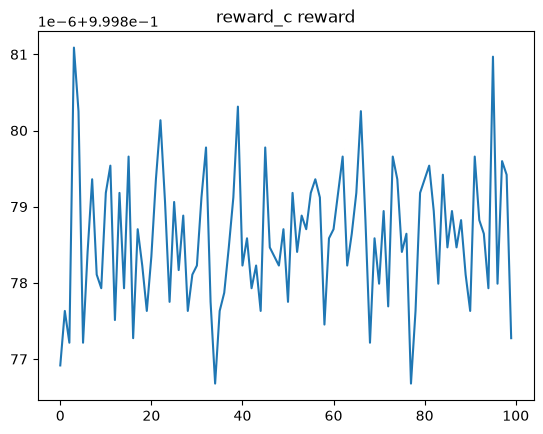

In [34]:
res_l = []
for fc in reward_fn_l:
    res = run_train(fc)
    res_l.append(res)
    plt.figure()
    plt.plot(res["reward_history"])
    plt.title(f"{res['func']} reward")
    plt.show()

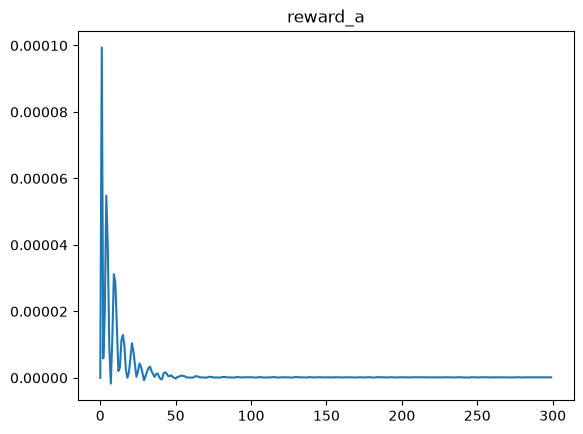

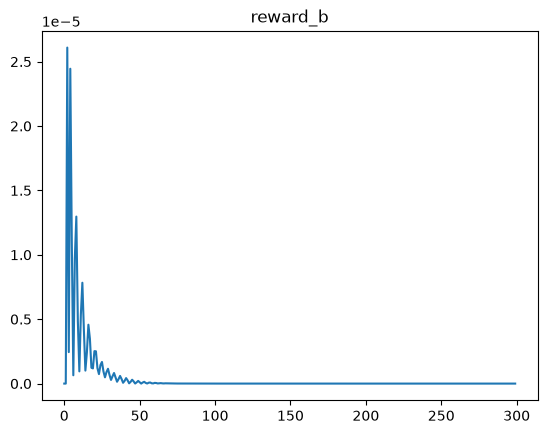

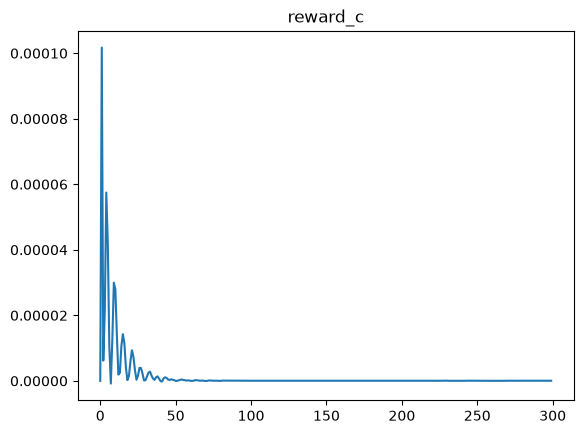

In [35]:
for e in res_l:
    loss = e["loss_history"]
    plt.plot(loss)
    plt.title(e["func"])
    plt.show()